# NB0 — Setup, Dataset & Smoke Test
____________________________________________________________________________________________________

**Project:** From Hand-Tuning to Architecture Search — CNN Design, Transfer Learning and Zero-Cost NAS for Satellite Land-Use Classification

For this project, we will use the **EuroSAT (RGB)** dataset.
It contains **27,000** Sentinel-2 satellite images of size **3x64x64** (3-channel color images of 64x64 pixels), split in **10 land-use classes**:
‘AnnualCrop’, ‘Forest’, ‘HerbaceousVegetation’, ‘Highway’, ‘Industrial’, ‘Pasture’, ‘PermanentCrop’, ‘Residential’, ‘River’, ‘SeaLake’.

The objectives of this notebook are the following:

a. Check the hardware (GPU) available on Kaggle

b. Load the EuroSAT dataset with ``torchvision.datasets.ImageFolder``

c. Build a **fixed, stratified** train / validation / test split and save it (`splits.json`) so that **every** notebook of the project uses exactly the same images

d. Compute the normalization statistics (mean / std) on the **training split only**

e. Show some of the training images

f. Smoke test: train a tiny CNN for 1 epoch to measure the time per epoch (useful to plan the compute budget)

## a. Hardware check

In [1]:
import os
import json
import time
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset

print("torch version      :", torch.__version__)
print("torchvision version:", torchvision.__version__)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

torch version      : 2.11.0+cu128
torchvision version: 0.26.0+cu128
Using device: cuda:0
GPU name: Tesla T4


**Reproducibility**

We fix all the random seeds (Python, NumPy, PyTorch) so that the split, the weight initialization and the shuffling are the same every time we run the notebook.

In [2]:
SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

## b. Loading the EuroSAT dataset

The dataset is attached to the Kaggle notebook (`waseemalastal/eurosat-rgb-dataset`). The images are stored in one folder per class:

```
EuroSAT_RGB/
├── AnnualCrop/AnnualCrop_1.jpg ...
├── Forest/Forest_1.jpg ...
└── ...
```

This is exactly the structure expected by ``torchvision.datasets.ImageFolder``: **the name of the folder is the label**.

In [3]:
# find the dataset folder (the mount path under /kaggle/input can change between Kaggle versions)
DATA_ROOT = None
for root, dirs, files in os.walk("/kaggle/input"):
    if os.path.basename(root) == "EuroSAT_RGB":
        DATA_ROOT = root
        break
print("DATA_ROOT:", DATA_ROOT)

DATA_ROOT: /kaggle/input/datasets/waseemalastal/eurosat-rgb-dataset/EuroSAT_RGB


In [4]:
# no transform for now: we only want to look at the raw data
full_dataset = torchvision.datasets.ImageFolder(root=DATA_ROOT)

classes = full_dataset.classes
num_classes = len(classes)
print("Number of images :", len(full_dataset))
print("Number of classes:", num_classes)
print("Classes:", classes)

# check the size of one image
img, label = full_dataset[0]
print("Image type:", type(img), "| size:", img.size, "| label:", label, "->", classes[label])

Number of images : 27000
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Image type: <class 'PIL.Image.Image'> | size: (64, 64) | label: 0 -> AnnualCrop


In [5]:
# number of images per class
targets = np.array(full_dataset.targets)  # label of every image, shape [27000]
for c in range(num_classes):
    print('%22s : %5d images' % (classes[c], (targets == c).sum()))

            AnnualCrop :  3000 images
                Forest :  3000 images
  HerbaceousVegetation :  3000 images
               Highway :  2500 images
            Industrial :  2500 images
               Pasture :  2000 images
         PermanentCrop :  2500 images
           Residential :  3000 images
                 River :  2500 images
               SeaLake :  3000 images


## c. Train / Validation / Test split

EuroSAT has no official split, so we create one ourselves:

| Split | Ratio | Used for |
|---|---|---|
| Train | 70% | updating the weights |
| Validation | 15% | choosing hyperparameters, early stopping, comparing configurations |
| Test | 15% | **only** the final evaluation (confusion matrix, final table) |

**Why stratified?**

A *stratified* split keeps the same proportion of each class in the 3 splits. The classes of EuroSAT are not perfectly balanced (2000 to 3000 images per class), so a random split could, by chance, give fewer images of one class in the test set.

**Why save the split?**

All the notebooks (baseline, architectures, augmentation, transfer learning, NAS) must be compared on **exactly the same test images**, otherwise the comparison is not fair.

In [6]:
from sklearn.model_selection import train_test_split

all_idx = np.arange(len(full_dataset))

# first: 70% train | 30% (val + test)
train_idx, temp_idx = train_test_split(all_idx, test_size=0.30, stratify=targets, random_state=SEED)
# then: split the 30% into 15% val | 15% test
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=targets[temp_idx], random_state=SEED)

print("train:", len(train_idx), "| val:", len(val_idx), "| test:", len(test_idx))

splits = {"train": train_idx.tolist(), "val": val_idx.tolist(), "test": test_idx.tolist(), "classes": classes, "seed": SEED}
with open("/kaggle/working/splits.json", "w") as f:
    json.dump(splits, f)
print("saved /kaggle/working/splits.json")

train: 18900 | val: 4050 | test: 4050
saved /kaggle/working/splits.json


In [7]:
# check: proportion of each class in each split (should be almost identical)
for c in range(num_classes):
    print('%22s : train %.3f | val %.3f | test %.3f' % (classes[c],
          (targets[train_idx] == c).mean(), (targets[val_idx] == c).mean(), (targets[test_idx] == c).mean()))

            AnnualCrop : train 0.111 | val 0.111 | test 0.111
                Forest : train 0.111 | val 0.111 | test 0.111
  HerbaceousVegetation : train 0.111 | val 0.111 | test 0.111
               Highway : train 0.093 | val 0.093 | test 0.093
            Industrial : train 0.093 | val 0.093 | test 0.093
               Pasture : train 0.074 | val 0.074 | test 0.074
         PermanentCrop : train 0.093 | val 0.093 | test 0.093
           Residential : train 0.111 | val 0.111 | test 0.111
                 River : train 0.093 | val 0.093 | test 0.093
               SeaLake : train 0.111 | val 0.111 | test 0.111


## d. Normalization statistics

In the labs we used ``transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))``, which maps [0, 1] to [-1, 1].
Here we compute the **real mean and standard deviation of each channel** (R, G, B) of EuroSAT, so that after normalization every channel has mean 0 and std 1.

We compute them on the **training split only**: the validation and test images must stay "unseen", otherwise information from the test set leaks into the preprocessing.

In [8]:
to_tensor_dataset = torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=transforms.ToTensor())
stats_loader = DataLoader(Subset(to_tensor_dataset, train_idx), batch_size=512, shuffle=False, num_workers=2)

channel_sum = torch.zeros(3)
channel_sq_sum = torch.zeros(3)
n_pixels = 0
for images, _ in stats_loader:
    # images: [B, 3, 64, 64] -> sum over batch, height and width (dims 0, 2, 3)
    channel_sum += images.sum(dim=(0, 2, 3))
    channel_sq_sum += (images ** 2).sum(dim=(0, 2, 3))
    n_pixels += images.size(0) * images.size(2) * images.size(3)

mean = channel_sum / n_pixels
std = torch.sqrt(channel_sq_sum / n_pixels - mean ** 2)  # Var[X] = E[X^2] - E[X]^2
print("mean:", mean.tolist())
print("std :", std.tolist())

splits["mean"] = mean.tolist()
splits["std"] = std.tolist()
with open("/kaggle/working/splits.json", "w") as f:
    json.dump(splits, f)

mean: [0.34390074014663696, 0.37995412945747375, 0.4075494110584259]
std : [0.20242466032505035, 0.1366828829050064, 0.11540823429822922]


## e. Let us show some of the training images

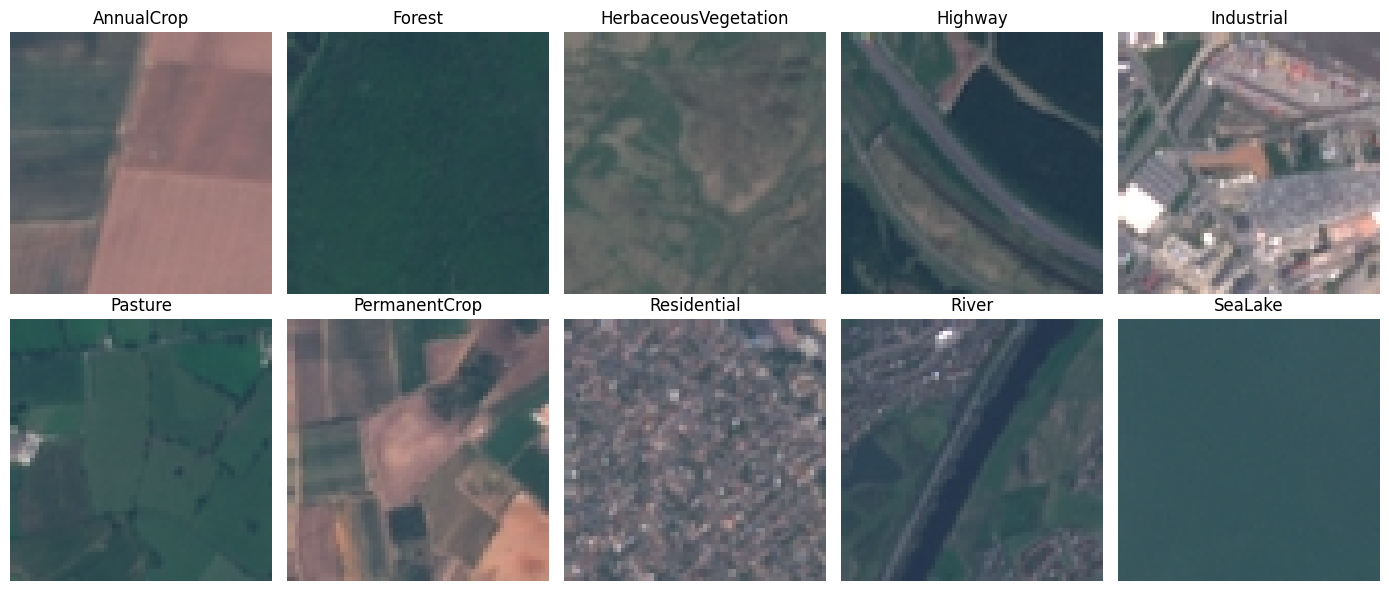

In [9]:
import matplotlib.pyplot as plt

# one example of each class
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for c, ax in enumerate(axes.flat):
    i = train_idx[targets[train_idx] == c][0]  # first training image of class c
    img, label = full_dataset[i]
    ax.imshow(img)
    ax.set_title(classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

## f. Smoke test: one epoch of a tiny CNN

We train a very small CNN for **1 epoch** only to check that the full pipeline works on the GPU and to measure the time per epoch.

In [10]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(splits["mean"], splits["std"])])

dataset = torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=transform)
trainloader = DataLoader(Subset(dataset, train_idx), batch_size=128, shuffle=True, num_workers=2)
valloader = DataLoader(Subset(dataset, val_idx), batch_size=256, shuffle=False, num_workers=2)


class TinyNet(nn.Module):
    def __init__(self):
        super(TinyNet, self).__init__()
        # input 3x64x64 | output 16x64x64 | h_out = (64 + 2*1 - 3)/1 + 1 = 64
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        # kernel=2x2, stride=2: the size is divided by 2
        self.pool = nn.MaxPool2d(2, 2)
        # input 16x32x32 | output 32x32x32
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        # after the 2nd pool: 32x16x16 -> flatten -> 32*16*16 = 8192 features
        self.fc = nn.Linear(32 * 16 * 16, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # 16x32x32
        x = self.pool(F.relu(self.conv2(x)))  # 32x16x16
        x = torch.flatten(x, 1)               # flatten all dimensions except batch
        x = self.fc(x)
        return x


net = TinyNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.9)

start = time.time()
net.train()
running_loss = 0.0
for i, data in enumerate(trainloader, 0):
    inputs, labels = data[0].to(device), data[1].to(device)
    optimizer.zero_grad()
    outputs = net(inputs)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()
    running_loss += loss.item()
epoch_time = time.time() - start

correct = 0
total = 0
net.eval()
with torch.no_grad():  # torch.no_grad for TESTING
    for data in valloader:
        images, labels = data[0].to(device), data[1].to(device)
        outputs = net(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('train loss: %.3f | val accuracy: %.2f %% | time for 1 epoch: %.1f s' % (
    running_loss / len(trainloader), 100 * correct / total, epoch_time))

train loss: 1.210 | val accuracy: 64.42 % | time for 1 epoch: 18.2 s


**Outputs of this notebook** (in `/kaggle/working`):
- `splits.json`: train / val / test indices, class names, mean and std. It is reused by all the other notebooks.